Mejor camino de La Défense a Place d'Italie:
La Défense -> Charles de Gaulle - Étoile -> Pigalle -> Barbès - Rochechouart -> Nation -> Place d'Italie
Número de tramos: 5


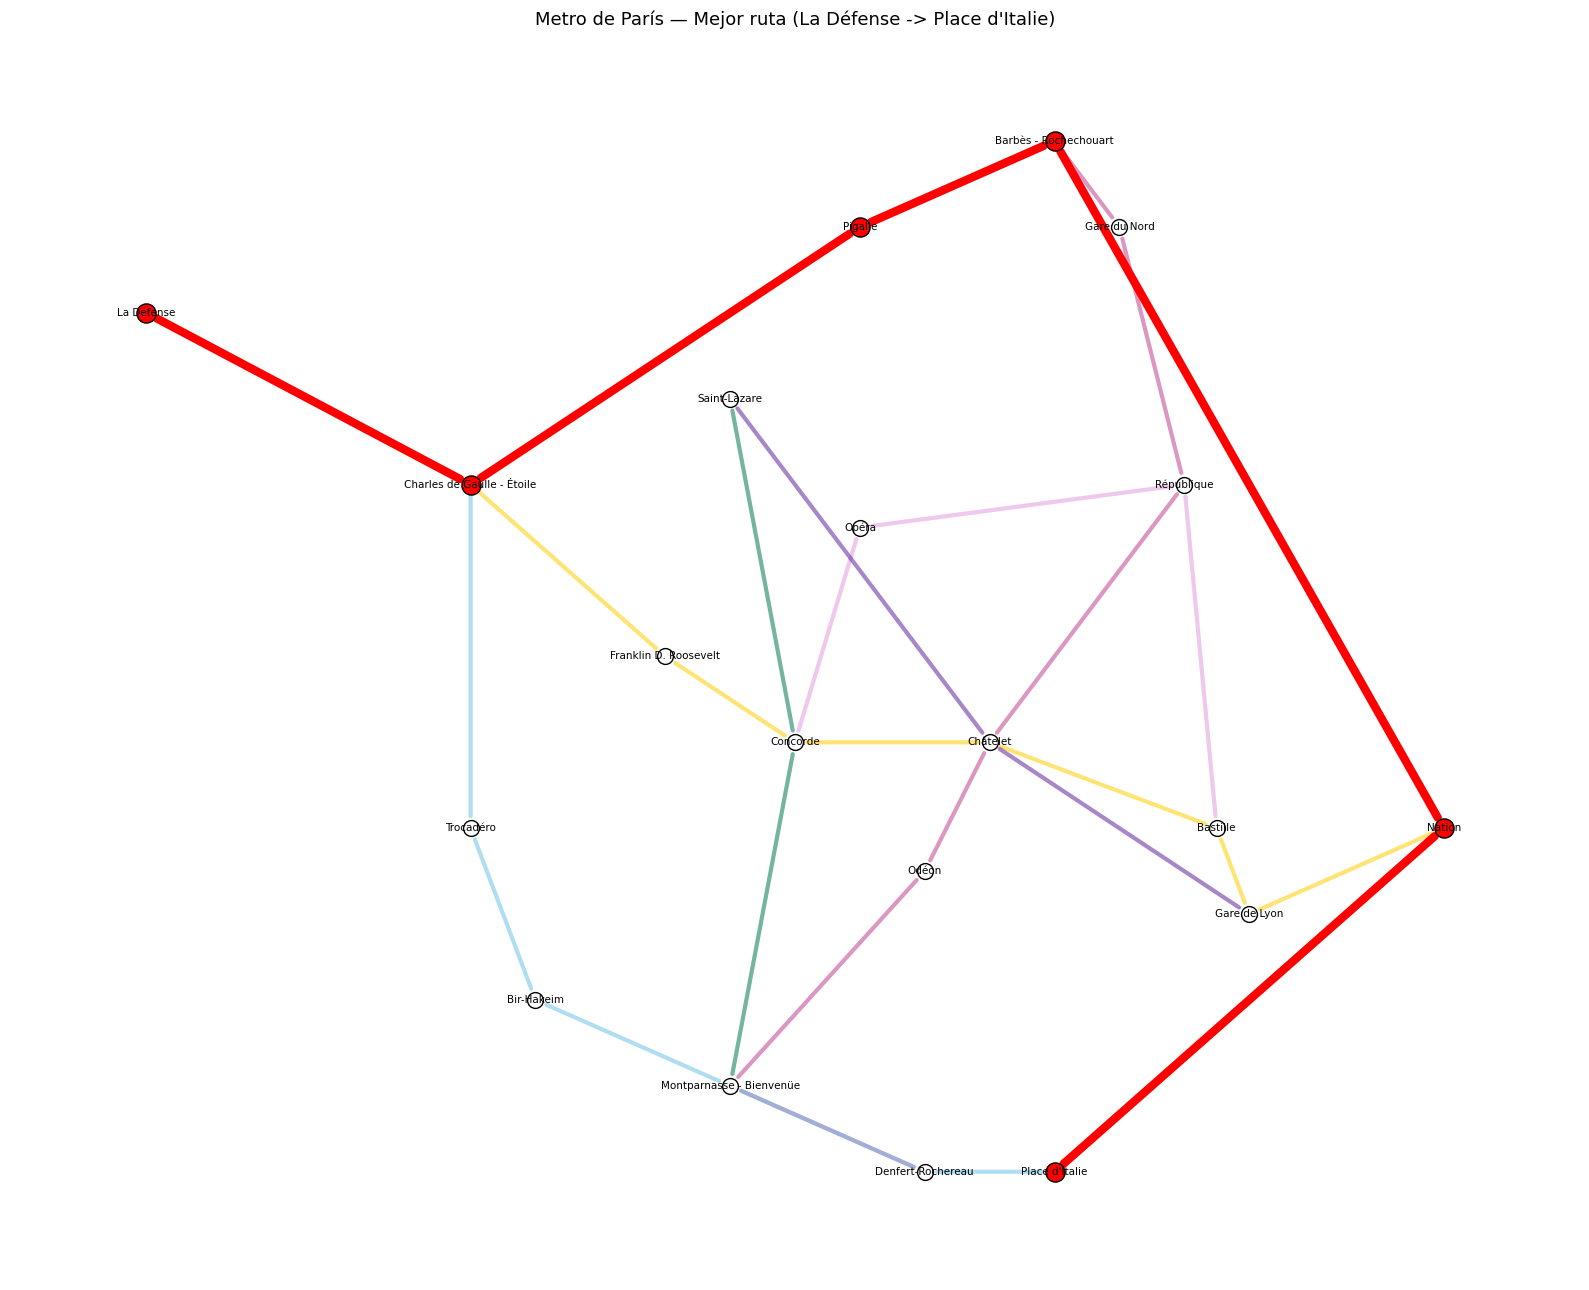

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. CREACIÓN DEL GRAFO DEL METRO DE PARÍS
G = nx.MultiGraph()

# Estaciones (nodos) con coordenadas aproximadas (x, y)
estaciones = {
    "La Défense": (-10, 5),
    "Charles de Gaulle - Étoile": (-5, 3),
    "Franklin D. Roosevelt": (-2, 1),
    "Concorde": (0, 0),
    "Châtelet": (3, 0),
    "Gare de Lyon": (7, -2),
    "Nation": (10, -1),
    "République": (6, 3),
    "Gare du Nord": (5, 6),
    "Saint-Lazare": (-1, 4),
    "Montparnasse - Bienvenüe": (-1, -4),
    "Place d'Italie": (4, -5),
    "Denfert-Rochereau": (2, -5),
    "Barbès - Rochechouart": (4, 7),
    "Pigalle": (1, 6),
    "Trocadéro": (-5, -1),
    "Bir-Hakeim": (-4, -3),
    "Odéon": (2, -1.5),
    "Bastille": (6.5, -1),
    "Opéra": (1, 2.5),
}

for est, coords in estaciones.items():
    G.add_node(est, pos=coords)

# Líneas del metro: nombre -> (color, lista de estaciones en orden)
lineas = {
    "Línea 1": (
        "#FFCD00",
        [
            "La Défense",
            "Charles de Gaulle - Étoile",
            "Franklin D. Roosevelt",
            "Concorde",
            "Châtelet",
            "Bastille",
            "Gare de Lyon",
            "Nation",
        ],
    ),
    "Línea 2": (
        "#003CA6",
        [
            "Charles de Gaulle - Étoile",
            "Pigalle",
            "Barbès - Rochechouart",
            "Nation",
        ],
    ),
    "Línea 4": (
        "#C04191",
        [
            "Barbès - Rochechouart",
            "Gare du Nord",
            "République",
            "Châtelet",
            "Odéon",
            "Montparnasse - Bienvenüe",
            "Denfert-Rochereau",
        ],
    ),
    "Línea 6": (
        "#6EC4E8",
        [
            "Charles de Gaulle - Étoile",
            "Trocadéro",
            "Bir-Hakeim",
            "Montparnasse - Bienvenüe",
            "Denfert-Rochereau",
            "Place d'Italie",
            "Nation",
        ],
    ),
    "Línea 8": (
        "#E19BDF",
        [
            "Concorde",
            "Opéra",
            "République",
            "Bastille",
        ],
    ),
    "Línea 12": (
        "#007852",
        [
            "Saint-Lazare",
            "Concorde",
            "Montparnasse - Bienvenüe",
        ],
    ),
    "Línea 14": (
        "#62259D",
        [
            "Saint-Lazare",
            "Châtelet",
            "Gare de Lyon",
        ],
    ),
}

# Agregar aristas por cada línea
for nombre, (color, parada_lista) in lineas.items():
    for i in range(len(parada_lista) - 1):
        u = parada_lista[i]
        v = parada_lista[i + 1]
        G.add_edge(u, v, linea=nombre, color=color, peso=1)

posiciones = nx.get_node_attributes(G, "pos")

# 2. BÚSQUEDA DEL MEJOR CAMINO CON DIJKSTRA
origen = "La Défense"
destino = "Place d'Italie"

mejor_camino = nx.shortest_path(G, source=origen, target=destino, weight="peso")
costo_total = nx.shortest_path_length(G, source=origen, target=destino, weight="peso")

print(f"Mejor camino de {origen} a {destino}:")
print(" -> ".join(mejor_camino))
print(f"Número de tramos: {costo_total}")

# 3. DIBUJAR EL GRAFO COMPLETO Y RESALTAR LA RUTA ÓPTIMA
plt.figure(figsize=(16, 13))

for nombre, (color, _) in lineas.items():
    aristas = [
        (u, v) for u, v, datos in G.edges(data=True) if datos["linea"] == nombre
    ]
    nx.draw_networkx_edges(
        G, posiciones, edgelist=aristas, edge_color=color, width=3, alpha=0.55
    )

# Resaltar en rojo el camino encontrado
aristas_camino = list(zip(mejor_camino[:-1], mejor_camino[1:]))
nx.draw_networkx_edges(
    G, posiciones, edgelist=aristas_camino, edge_color="red", width=6
)
nx.draw_networkx_nodes(
    G, posiciones, node_size=130, node_color="white", edgecolors="black"
)
nx.draw_networkx_nodes(
    G, posiciones, nodelist=mejor_camino, node_size=190, node_color="red", edgecolors="black"
)
nx.draw_networkx_labels(G, posiciones, font_size=7.5)

plt.title(f"Metro de París — Mejor ruta ({origen} -> {destino})", fontsize=13)
plt.axis("off")
plt.tight_layout()
plt.show()